# Example of the aitlas toolbox in the context of image segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import BioMasstersDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Sentinel-2

Total number of patches: 6827


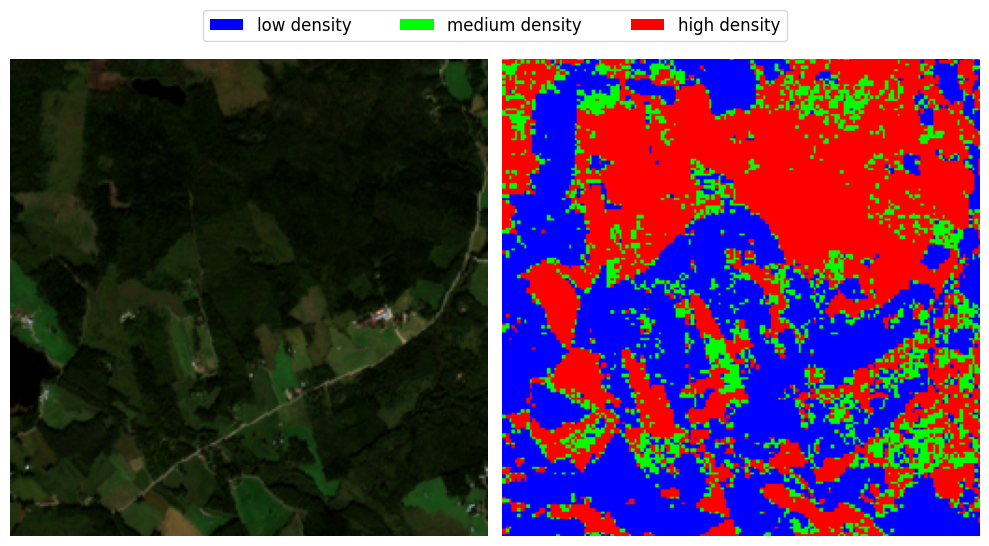

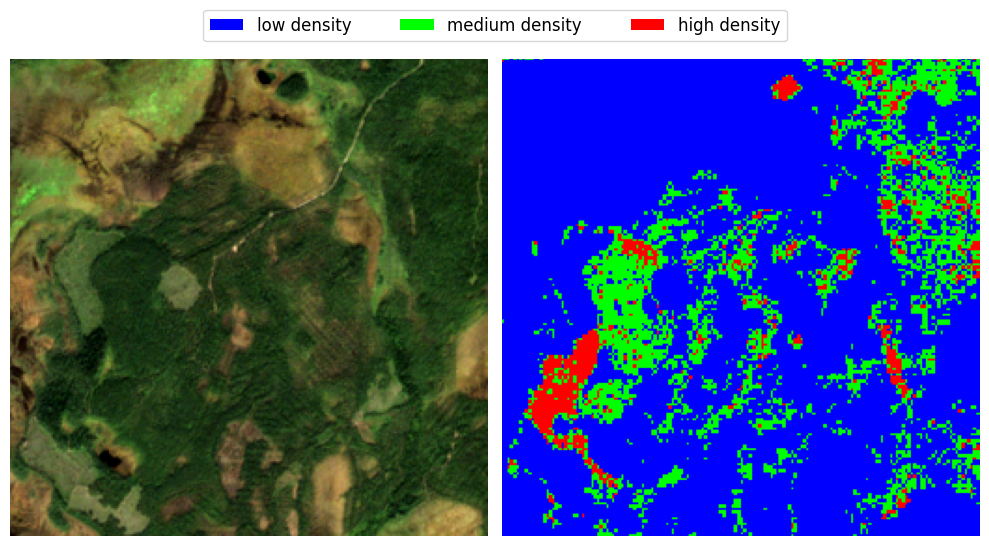

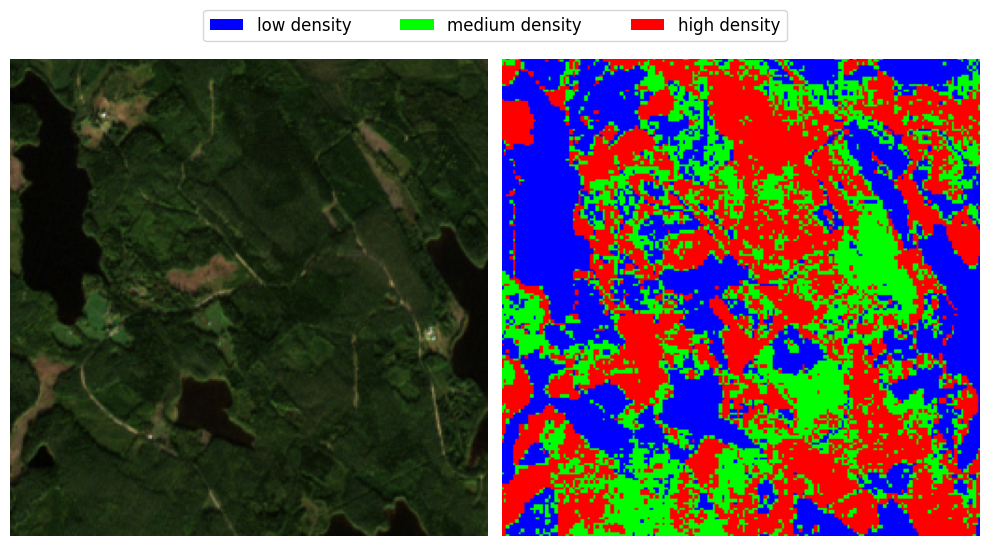

In [108]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/biomassters/train_features",
    "annotation_dir": "/home/dragik/data/FAIR_EO/biomassters/train_agbm",
    "timeseries": "False",
    "imagery": "S2",
    "selection": "rgb"
}
dataset = BioMasstersDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(15);
dataset.show_image(1000);
dataset.show_image(25);

Sentinel-1

Total number of patches: 8642


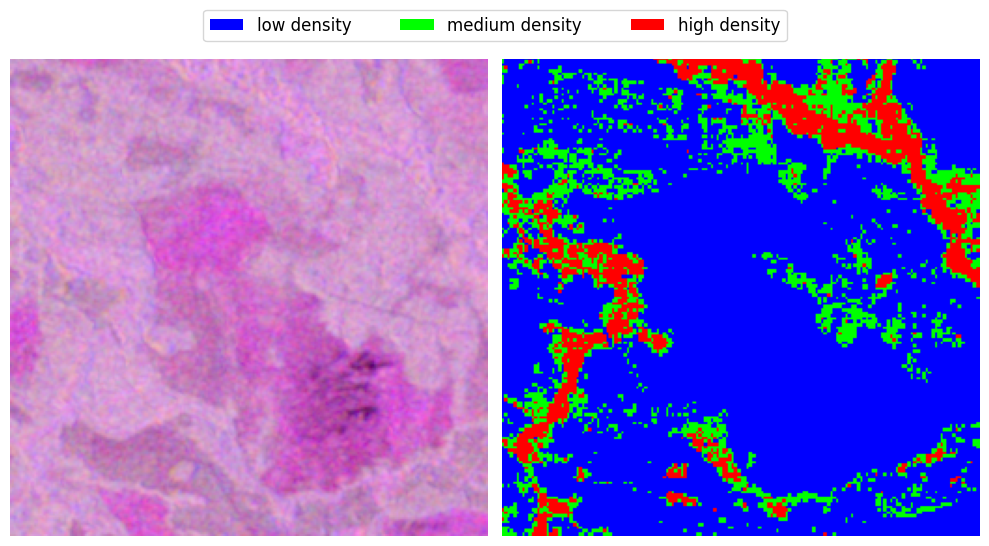

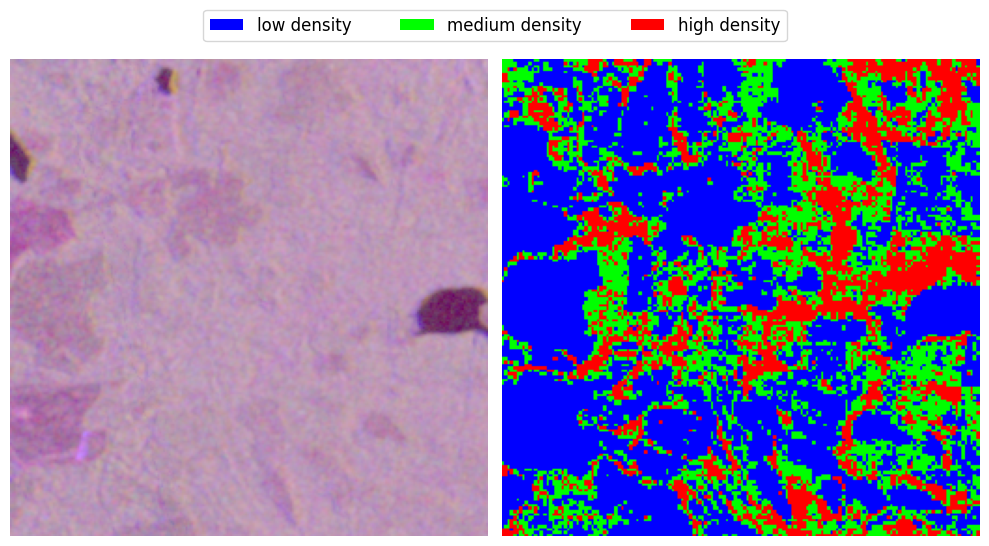

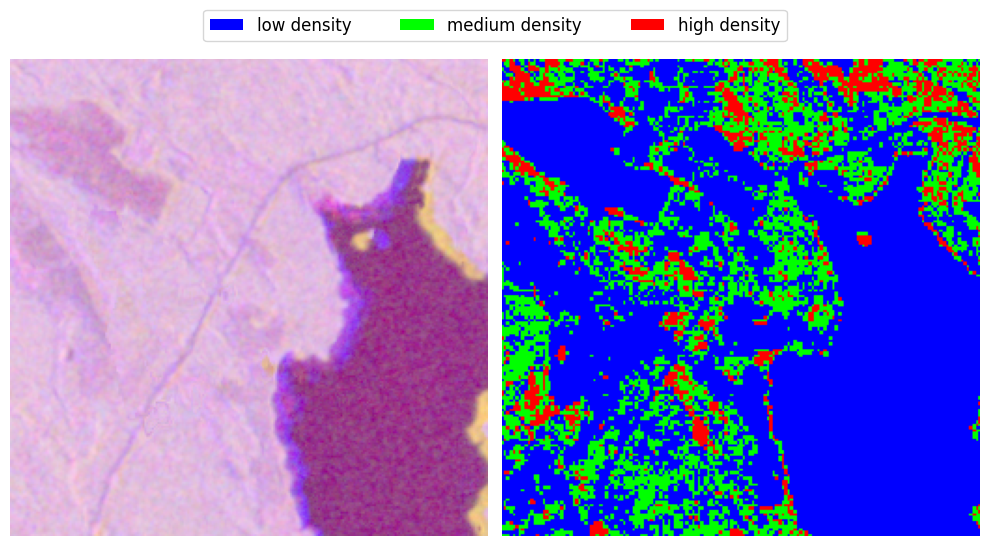

In [87]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/biomassters/train_features",
    "annotation_dir": "/home/dragik/data/FAIR_EO/biomassters/train_agbm",
    "timeseries": "False",
    "imagery": "S1",
    "selection": "rgb"
}
dataset = BioMasstersDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(15);
dataset.show_image(300);
dataset.show_image(25);

Sentinel-2 and Sentinel-1 pairs

Total number of patches: 6826


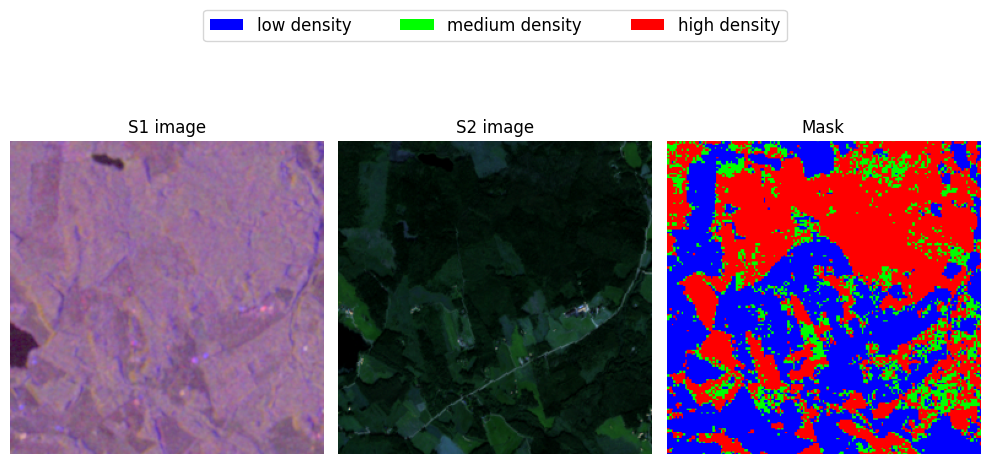

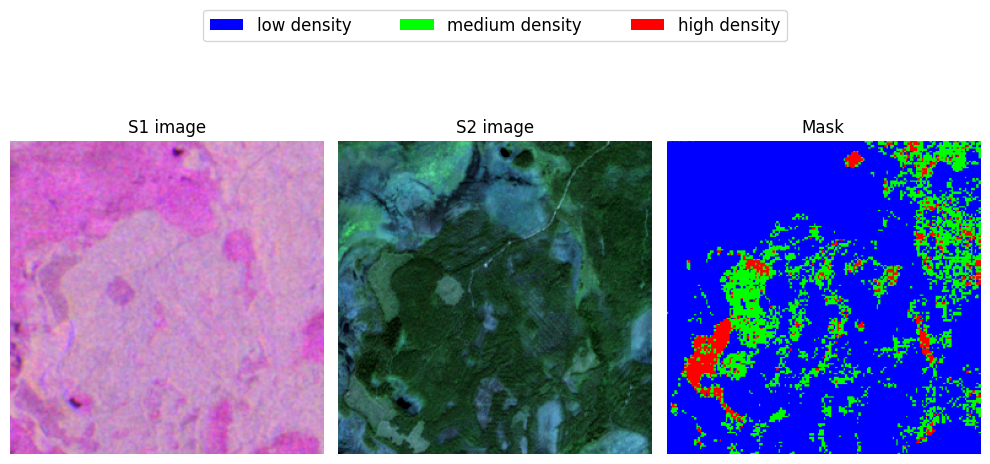

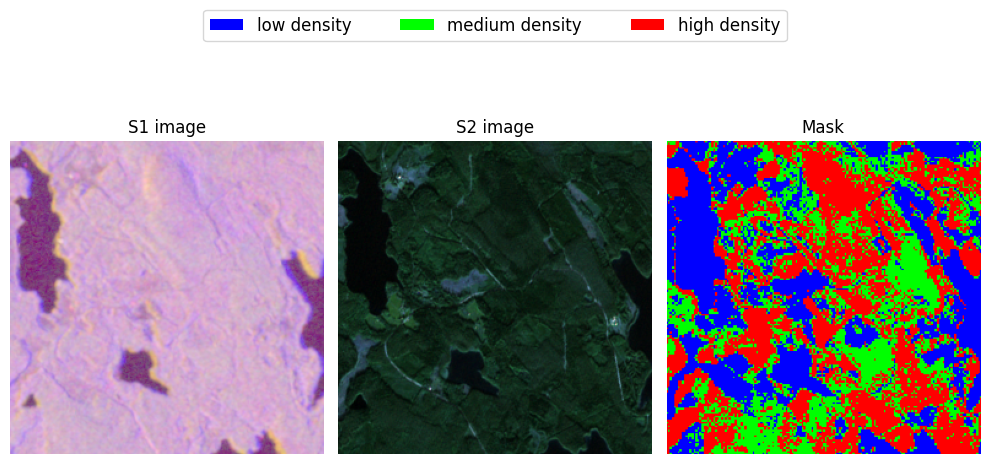

In [109]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/biomassters/train_features",
    "annotation_dir": "/home/dragik/data/FAIR_EO/biomassters/train_agbm",
    "timeseries": "False",
    "imagery": "all"
}
dataset = BioMasstersDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(15);
dataset.show_image(1000);
dataset.show_image(25);

In [53]:
dataset.data_distribution_table()

,Number of pixels
low density,344902023.0
medium density,107514865.0
high density,113945224.0


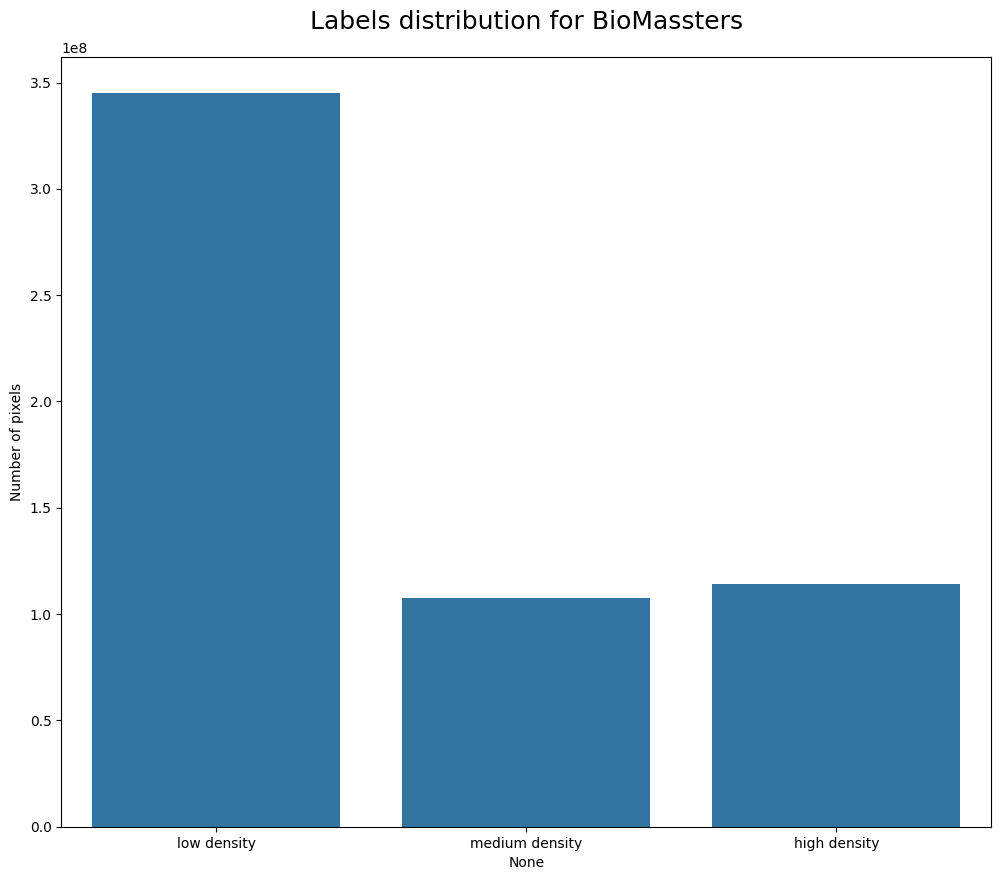

In [54]:
dataset.data_distribution_barchart();

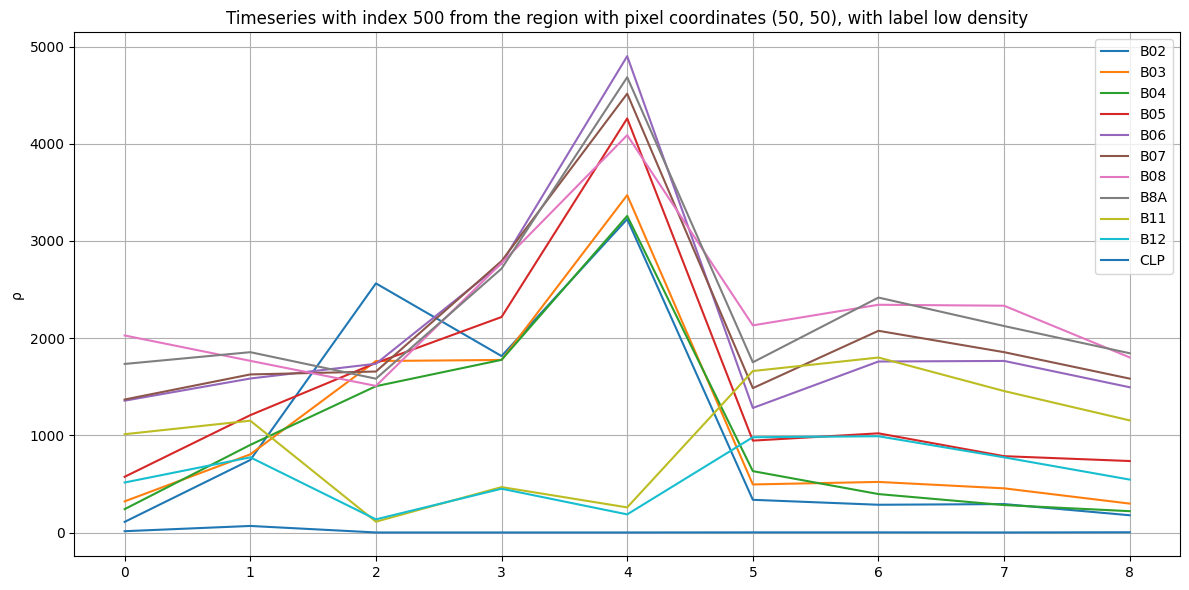

In [142]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/biomassters/train_features",
    "annotation_dir": "/home/dragik/data/FAIR_EO/biomassters/train_agbm",
    "timeseries": "True",
    "imagery": "S2",
    "selection": "all"
}
dataset = BioMasstersDataset(dataset_config)

dataset.show_timeseries(500, 50, 50);

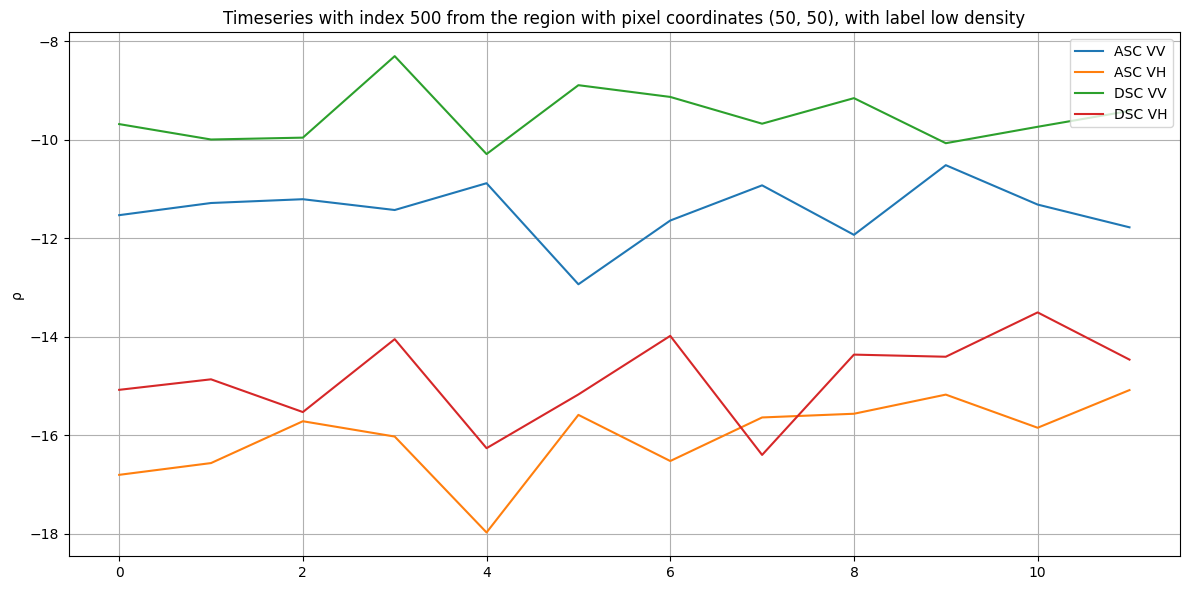

In [143]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/biomassters/train_features",
    "annotation_dir": "/home/dragik/data/FAIR_EO/biomassters/train_agbm",
    "timeseries": "True",
    "imagery": "S1",
    "selection": "all"
}
dataset = BioMasstersDataset(dataset_config)

dataset.show_timeseries(500, 50, 50);

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 23,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/biomassters/train_features",
    "annotation_dir": "/home/dragik/data/FAIR_EO/biomassters/train_agbm",
    "imagery": "S2",
    "timeseries": False,
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = BioMasstersDataset(train_dataset_config)

len(train_dataset)

6827

## Create the model ##

In [148]:
epochs = 20
model_directory = "/home/dragik/data/FAIR_EO/experiments/biomassters"
model_config = {
    "num_classes": 3, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [149]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2026-05-25 10:04:03,540 INFO Starting training.
training: 100%|██████████| 297/297 [01:05<00:00,  4.50it/s]
2026-05-25 10:05:09,552 INFO epoch: 1, time: 66, loss:  0.50036
testing on train set: 100%|██████████| 297/297 [00:26<00:00, 11.36it/s]
2026-05-25 10:05:37,712 INFO IOU:0.37099028691749475, IOU mean:0.2705991823203126, IOU per Class:[0.60265754 0.         0.20914   ]
training: 100%|██████████| 297/297 [01:06<00:00,  4.47it/s]
2026-05-25 10:06:44,138 INFO epoch: 2, time: 67, loss:  0.42821
testing on train set: 100%|██████████| 297/297 [00:24<00:00, 11.98it/s]
2026-05-25 10:07:08,953 INFO IOU:0.4312286181360675, IOU mean:0.2008629994338982, IOU per Class:[0.602589 0.       0.      ]
training: 100%|██████████| 297/297 [01:06<00:00,  4.48it/s]
2026-05-25 10:08:15,281 INFO epoch: 3, time: 67, loss:  0.40714
testing on train set: 100%|██████████| 297/297 [00:24<00:00, 11.93it/s]
2026-05-25 10:08:40,198 INFO IOU:0.43128564409820513, IOU mean:0.2008854645657122, IOU per Class:[0.6026563

0.39739299608006806

## Predictions ##

2026-05-25 10:35:02,961 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/biomassters/checkpoint.pth.tar
2026-05-25 10:35:03,390 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/biomassters/checkpoint.pth.tar at epoch 21


2773


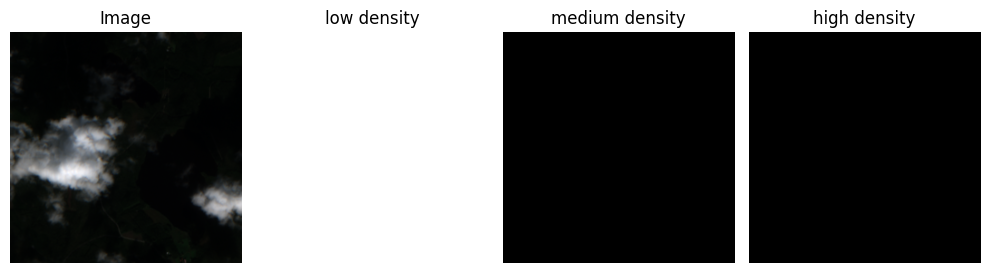

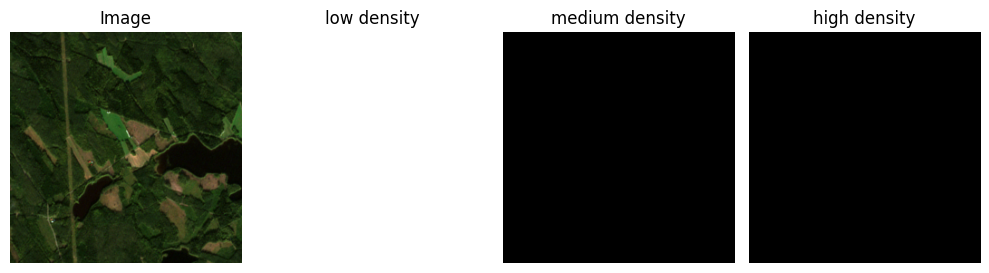

In [150]:
model_path = "/home/dragik/data/FAIR_EO/experiments/biomassters/checkpoint.pth.tar"
labels = ["low density","medium density","high density"]
transform = ResizeToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/biomassters/test_features",
    "annotation_dir": "/home/dragik/data/FAIR_EO/biomassters/test_agbm",
    "imagery": "S2",
    "timeseries": False,
    "selection": "rgb",
}
test_dataset = BioMasstersDataset(test_dataset_config)

print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_masks(image, labels, transform)
image = test_dataset[10][0]
fig = model.predict_masks(image, labels, transform)